# LGBM abundance models with Optuna and feature importance

This notebook combines the main ideas from `ML_abundances_fe_final.ipynb` and `ML_abundances_fe_final_features.ipynb` for the specific chemistry-only model using:

- `fe_h`
- `mg_h`
- `si_h`

Targets:

- `o_h`
- `c_h`

For each target, the notebook:

1. tunes `LGBMRegressor` hyperparameters with Optuna on APOGEE
2. fits the best model on APOGEE
3. evaluates on APOGEE holdout and HARPS
4. measures feature importance with built-in gain, permutation importance, SHAP, and single-feature predictive power
5. makes abundance and residual plots similar to the earlier notebooks


In [6]:
import json
from copy import deepcopy
from pathlib import Path

import joblib
import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap

from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split


In [7]:
plt.style.use("seaborn-v0_8-white")
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.dpi": 140,
})

RANDOM_STATE = 42
FEATURES = ["fe_h", "mg_h", "si_h"]
FEATURE_TAG = "fe_mg_si"
TARGETS = ["o_h", "c_h"]
N_TRIALS = 10
N_SPLITS = 5
PERMUTATION_REPEATS = 5
OUTPUT_ROOT = f"optuna_feature_outputs_{FEATURE_TAG}"
MODEL_DIR = "models"
SHAP_DEPENDENCE_PAIRS = [("mg_h", "fe_h")]


In [8]:
PRETTY_LABELS = {
    "fe_h": r"$[\mathrm{Fe/H}]$",
    "mg_h": r"$[\mathrm{Mg/H}]$",
    "si_h": r"$[\mathrm{Si/H}]$",
    "o_h": r"$[\mathrm{O/H}]$",
    "c_h": r"$[\mathrm{C/H}]$",
}


def get_elfe_label(target):
    if target == "o_h":
        return r"$[\mathrm{O/Fe}]$"
    if target == "c_h":
        return r"$[\mathrm{C/Fe}]$"
    return target


def ensure_dir(path):
    Path(path).mkdir(parents=True, exist_ok=True)


## Load and clean data

In [9]:
apogee = pd.read_csv("apogee_sample.csv")
harps = pd.read_csv("harps_sample.csv")

print(f"Raw APOGEE rows: {len(apogee)}")
print(f"Raw HARPS rows:  {len(harps)}")


Raw APOGEE rows: 95586
Raw HARPS rows:  798


In [10]:
def clean_survey_data(df, survey_name):
    df = df.copy()
    df = df[df["parallax"] > 0.0]
    df["rel_parallax"] = df["parallax_error"] / df["parallax"]
    df = df[df["rel_parallax"] < 0.1]

    if survey_name.lower() == "apogee":
        df = df[df["logg"] < 3]

    df = df[df["zmax"] < 10]
    return df


apogee = clean_survey_data(apogee, "apogee")
harps = clean_survey_data(harps, "harps")

# Derived chemistry features for the extended model.
apogee["mg_fe"] = apogee["mg_h"] - apogee["fe_h"]
apogee["mg_si"] = apogee["mg_h"] - apogee["si_h"]
harps["mg_fe"] = harps["mg_h"] - harps["fe_h"]
harps["mg_si"] = harps["mg_h"] - harps["si_h"]

print(f"Clean APOGEE rows: {len(apogee)}")
print(f"Clean HARPS rows:  {len(harps)}")
print(f"Features used: {FEATURES}")


Clean APOGEE rows: 45727
Clean HARPS rows:  798
Features used: ['fe_h', 'mg_h', 'si_h']


## Helpers

In [11]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def compute_metrics(y_true, y_pred):
    return {
        "rmse": rmse(y_true, y_pred),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "r2": float(r2_score(y_true, y_pred)),
    }


def prepare_element_data(apogee_df, harps_df, target, features=FEATURES):
    cols = features + [target]
    ap = apogee_df[cols].dropna().copy()
    ha = harps_df[cols].dropna().copy()
    return ap[features], ap[target], ha[features], ha[target]


def build_lgbm(params, random_state=RANDOM_STATE):
    final_params = deepcopy(params)
    final_params["random_state"] = random_state
    final_params["verbosity"] = -1
    final_params["n_jobs"] = -1
    return LGBMRegressor(**final_params)


def save_series(series, out_csv):
    df = pd.DataFrame({
        "feature": series.index,
        "feature_pretty": [PRETTY_LABELS.get(f, f) for f in series.index],
        "value": series.values,
    })
    df.to_csv(out_csv, index=False)


def plot_barh(series, title, xlabel, outpath, ascending=False):
    s = series.sort_values(ascending=ascending)
    labels = [PRETTY_LABELS.get(f, f) for f in s.index]

    plt.figure(figsize=(8, 5))
    plt.barh(labels, s.values, color="steelblue")
    plt.title(title, weight="bold")
    plt.xlabel(xlabel, weight="bold")
    plt.tight_layout()
    plt.savefig(outpath, bbox_inches="tight")
    plt.show()


## Optuna tuning

In [12]:
def cv_rmse(model, X, y, n_splits=N_SPLITS, random_state=RANDOM_STATE):
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scores = []
    for tr, te in cv.split(X, y):
        fitted = clone(model)
        fitted.fit(X.iloc[tr], y.iloc[tr])
        pred = fitted.predict(X.iloc[te])
        scores.append(rmse(y.iloc[te], pred))
    return float(np.mean(scores))


def objective_lgbm(trial, X, y):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 16, 256),
        "max_depth": trial.suggest_int("max_depth", -1, 16),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 200),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 50.0, log=True),
    }
    model = build_lgbm(params)
    return cv_rmse(model, X, y)


def tune_lgbm_for_target(X, y, target, n_trials=N_TRIALS):
    study = optuna.create_study(direction="minimize", study_name=f"LGBM_{target}_fe_mg_si")
    study.optimize(lambda trial: objective_lgbm(trial, X, y), n_trials=n_trials, show_progress_bar=False)
    return study


## Importance methods

In [13]:
def builtin_gain_importance(model, feature_names):
    values = model.booster_.feature_importance(importance_type="gain")
    return pd.Series(values, index=feature_names).sort_values(ascending=False)


def permutation_importance_drmse(model, X, y, n_repeats=PERMUTATION_REPEATS, random_state=RANDOM_STATE):
    perm = permutation_importance(
        model,
        X,
        y,
        scoring="neg_root_mean_squared_error",
        n_repeats=n_repeats,
        random_state=random_state,
        n_jobs=-1,
    )
    delta_rmse = -perm.importances_mean
    return pd.Series(delta_rmse, index=X.columns).sort_values(ascending=False)


def shap_global_importance(model, X):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)
    if isinstance(shap_values, list):
        shap_values = shap_values[0]
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    return pd.Series(mean_abs_shap, index=X.columns).sort_values(ascending=False)


def single_feature_cv_rmse(best_params, X, y, random_state=RANDOM_STATE):
    splitter = KFold(n_splits=N_SPLITS, shuffle=True, random_state=random_state)
    out = {}
    for feature in X.columns:
        model = build_lgbm(best_params, random_state=random_state)
        scores = cross_val_score(
            model,
            X[[feature]],
            y,
            cv=splitter,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
        )
        out[feature] = -scores.mean()
    return pd.Series(out).sort_values(ascending=True)


## Plotting helpers

In [14]:
def plot_prediction_panels(X, y_true, y_pred, target, sample_name, save_path=None, color="tab:blue"):
    feh = np.asarray(X["fe_h"]).astype(float)
    mgh = np.asarray(X["mg_h"]).astype(float)
    y_true = np.asarray(y_true).astype(float)
    y_pred = np.asarray(y_pred).astype(float)

    y_base = mgh.copy()
    elfe_true = y_true - feh
    elfe_pred = y_pred - feh
    resid_model = y_true - y_pred
    resid_base = y_true - y_base

    rmse_model = rmse(y_true, y_pred)
    rmse_base = rmse(y_true, y_base)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

    axes[0].scatter(feh, elfe_true, s=20, alpha=0.35, color="lightgray", label="True")
    axes[0].scatter(feh, elfe_pred, s=20, alpha=0.45, color=color, label="Predicted")
    axes[0].axhline(0.0, ls="--", lw=1.0, color="black")
    axes[0].set_xlabel(PRETTY_LABELS["fe_h"])
    axes[0].set_ylabel(get_elfe_label(target))
    axes[0].set_title(sample_name)
    axes[0].legend(frameon=False)

    mask = (feh > -0.8) & (feh < 0.35)
    y_true_res = y_true[mask]
    resid_model_res = resid_model[mask]
    resid_base_res = resid_base[mask]

    axes[1].scatter(y_true_res, resid_model_res, s=20, alpha=0.45, color=color)
    #axes[1].scatter(y_true_res, resid_base_res, s=18, alpha=0.25, color="gray", label="[Mg/H] baseline")
    axes[1].axhline(0.0, ls="--", lw=1.0, color="black")
    axes[1].set_xlabel(f"True {PRETTY_LABELS[target]}")
    axes[1].set_ylabel(f"Residual ({PRETTY_LABELS[target]} true - pred)")
    axes[1].set_title("Residuals")
    #axes[1].legend(frameon=False)
    axes[1].text(
        0.03,
        0.97,
        rf"$\mathrm{{RMSE}}_{{\rm model}} = {rmse_model:.3f}$ dex" + "\n" + rf"$\mathrm{{RMSE}}_{{\rm [Mg/H]}} = {rmse_base:.3f}$ dex",
        transform=axes[1].transAxes,
        va="top",
    )

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_shap_summary(model, X, target, outpath=None):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)
    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    plt.figure(figsize=(8, 5))
    shap.summary_plot(shap_values, X, show=False)
    plt.title(f"SHAP summary for {target}")
    if outpath is not None:
        plt.savefig(outpath, dpi=300, bbox_inches="tight")
    plt.show()


def make_shap_dependence_plot(model, X, feature, interaction_feature, outpath=None):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)
    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    plt.figure(figsize=(8, 6))
    shap.dependence_plot(feature, shap_values, X, interaction_index=interaction_feature, show=False)
    fig = plt.gcf()
    ax = fig.axes[0]
    ax.set_xlabel(PRETTY_LABELS.get(feature, feature))
    ax.set_ylabel(f"SHAP value for {PRETTY_LABELS.get(feature, feature)}")
    if len(fig.axes) > 1:
        cax = fig.axes[-1]
        cax.set_ylabel(PRETTY_LABELS.get(interaction_feature, interaction_feature))
    plt.tight_layout()
    if outpath is not None:
        plt.savefig(outpath, dpi=300, bbox_inches="tight")
    plt.show()


def run_shap_dependence_plots(model, X, target_dir, target, dependence_pairs=SHAP_DEPENDENCE_PAIRS, dataset_name="apogee_full"):
    for feature, interaction_feature in dependence_pairs:
        outpath = target_dir / f"shap_dependence_{dataset_name}_{FEATURE_TAG}_{target}_{feature}_by_{interaction_feature}.png"
        make_shap_dependence_plot(model, X, feature=feature, interaction_feature=interaction_feature, outpath=outpath)


## Full run for one target

In [15]:
def run_target_pipeline(apogee_df, harps_df, target, out_root=OUTPUT_ROOT, model_dir=MODEL_DIR):
    ensure_dir(out_root)
    ensure_dir(model_dir)
    target_dir = Path(out_root) / target
    ensure_dir(target_dir)

    X_ap, y_ap, X_ha, y_ha = prepare_element_data(apogee_df, harps_df, target, features=FEATURES)

    X_train, X_test, y_train, y_test = train_test_split(
        X_ap,
        y_ap,
        test_size=0.2,
        random_state=RANDOM_STATE,
    )

    study = tune_lgbm_for_target(X_train, y_train, target=target, n_trials=N_TRIALS)
    best_params = study.best_params

    params_path = Path(model_dir) / f"lgbm_{FEATURE_TAG}_best_params_{target}.json"
    with open(params_path, "w") as f:
        json.dump({"target": target, "feature_tag": FEATURE_TAG, "features": FEATURES, "best_value": study.best_value, "best_params": best_params}, f, indent=2)

    model_apogee = build_lgbm(best_params)
    model_apogee.fit(X_train, y_train)

    apogee_pred = model_apogee.predict(X_test)
    apogee_metrics = compute_metrics(y_test, apogee_pred)

    model_full = build_lgbm(best_params)
    model_full.fit(X_ap, y_ap)
    harps_pred = model_full.predict(X_ha)
    harps_metrics = compute_metrics(y_ha, harps_pred)

    model_apogee_holdout_path = Path(model_dir) / f"lgbm_{FEATURE_TAG}_apogee_holdout_{target}.joblib"
    model_full_apogee_path = Path(model_dir) / f"lgbm_{FEATURE_TAG}_full_apogee_{target}.joblib"
    joblib.dump(model_apogee, model_apogee_holdout_path)
    joblib.dump(model_full, model_full_apogee_path)

    builtin = builtin_gain_importance(model_apogee, X_train.columns)
    perm = permutation_importance_drmse(model_apogee, X_test, y_test)
    shap_imp = shap_global_importance(model_apogee, X_test)
    single = single_feature_cv_rmse(best_params, X_ap, y_ap)

    summary = pd.concat([
        builtin.rename("builtin_gain"),
        perm.rename("permutation_drmse"),
        shap_imp.rename("shap_mean_abs"),
        single.rename("single_feature_cv_rmse"),
    ], axis=1)
    summary["builtin_rank"] = summary["builtin_gain"].rank(ascending=False, method="min")
    summary["permutation_rank"] = summary["permutation_drmse"].rank(ascending=False, method="min")
    summary["shap_rank"] = summary["shap_mean_abs"].rank(ascending=False, method="min")
    summary["single_feature_rank"] = summary["single_feature_cv_rmse"].rank(ascending=True, method="min")
    summary.to_csv(target_dir / f"importance_summary_{FEATURE_TAG}_{target}.csv")

    save_series(builtin, target_dir / f"builtin_gain_{FEATURE_TAG}_{target}.csv")
    save_series(perm, target_dir / f"permutation_drmse_{FEATURE_TAG}_{target}.csv")
    save_series(shap_imp, target_dir / f"shap_mean_abs_{FEATURE_TAG}_{target}.csv")
    save_series(single, target_dir / f"single_feature_cv_rmse_{FEATURE_TAG}_{target}.csv")

    plot_barh(builtin.sort_values(ascending=True), f"Built-in importance (gain)", "Importance (relative units)", target_dir / f"builtin_gain_{FEATURE_TAG}_{target}.png")
    plot_barh(perm.sort_values(ascending=True), f"Permutation importance", r"$\Delta$RMSE", target_dir / f"permutation_drmse_{FEATURE_TAG}_{target}.png")
    plot_barh(shap_imp.sort_values(ascending=True), f"SHAP global importance", r"Mean $|\mathrm{SHAP}|$", target_dir / f"shap_mean_abs_{FEATURE_TAG}_{target}.png")
    plot_barh(single.sort_values(ascending=False), f"Single-feature predictive power", "RMSE", target_dir / f"single_feature_cv_rmse_{FEATURE_TAG}_{target}.png")

    plot_prediction_panels(X_test, y_test, apogee_pred, target, sample_name="APOGEE holdout", save_path=target_dir / f"prediction_panels_apogee_holdout_{FEATURE_TAG}_{target}.png", color="#1f77b4")
    plot_prediction_panels(X_ha, y_ha, harps_pred, target, sample_name="HARPS", save_path=target_dir / f"prediction_panels_harps_{FEATURE_TAG}_{target}.png", color="#ff7f0e")
    plot_shap_summary(model_apogee, X_test, target, outpath=target_dir / f"shap_summary_{FEATURE_TAG}_{target}.png")
    run_shap_dependence_plots(model_full, X_ap, target_dir=target_dir, target=target, dependence_pairs=SHAP_DEPENDENCE_PAIRS, dataset_name="apogee_full")

    return {
        "target": target,
        "study": study,
        "best_params": best_params,
        "params_path": str(params_path),
        "model_apogee_holdout_path": str(model_apogee_holdout_path),
        "model_full_apogee_path": str(model_full_apogee_path),
        "apogee_metrics": apogee_metrics,
        "harps_metrics": harps_metrics,
        "importance_summary": summary,
        "model_apogee": model_apogee,
        "model_full": model_full,
        "X_test": X_test,
        "y_test": y_test,
        "apogee_pred": apogee_pred,
        "X_harps": X_ha,
        "y_harps": y_ha,
        "harps_pred": harps_pred,
    }


## Run both targets

[I 2026-03-17 13:23:14,354] A new study created in memory with name: LGBM_o_h_fe_mg_si


Running pipeline for o_h


[I 2026-03-17 13:25:18,398] Trial 0 finished with value: 0.03730148031274903 and parameters: {'n_estimators': 729, 'learning_rate': 0.07140784117124688, 'num_leaves': 251, 'max_depth': 7, 'min_child_samples': 19, 'subsample': 0.6401326230216708, 'colsample_bytree': 0.5377819293875196, 'reg_alpha': 7.1116536982475695e-06, 'reg_lambda': 0.053228988834915225}. Best is trial 0 with value: 0.03730148031274903.
[I 2026-03-17 13:26:24,458] Trial 1 finished with value: 0.03650271167822487 and parameters: {'n_estimators': 468, 'learning_rate': 0.04674615891923399, 'num_leaves': 80, 'max_depth': 13, 'min_child_samples': 122, 'subsample': 0.8120397241218519, 'colsample_bytree': 0.9020815514240887, 'reg_alpha': 0.0165579806373722, 'reg_lambda': 3.6686728884833596e-07}. Best is trial 1 with value: 0.03650271167822487.
[I 2026-03-17 13:27:56,900] Trial 2 finished with value: 0.03679891295910358 and parameters: {'n_estimators': 482, 'learning_rate': 0.08862692005547992, 'num_leaves': 122, 'max_depth'

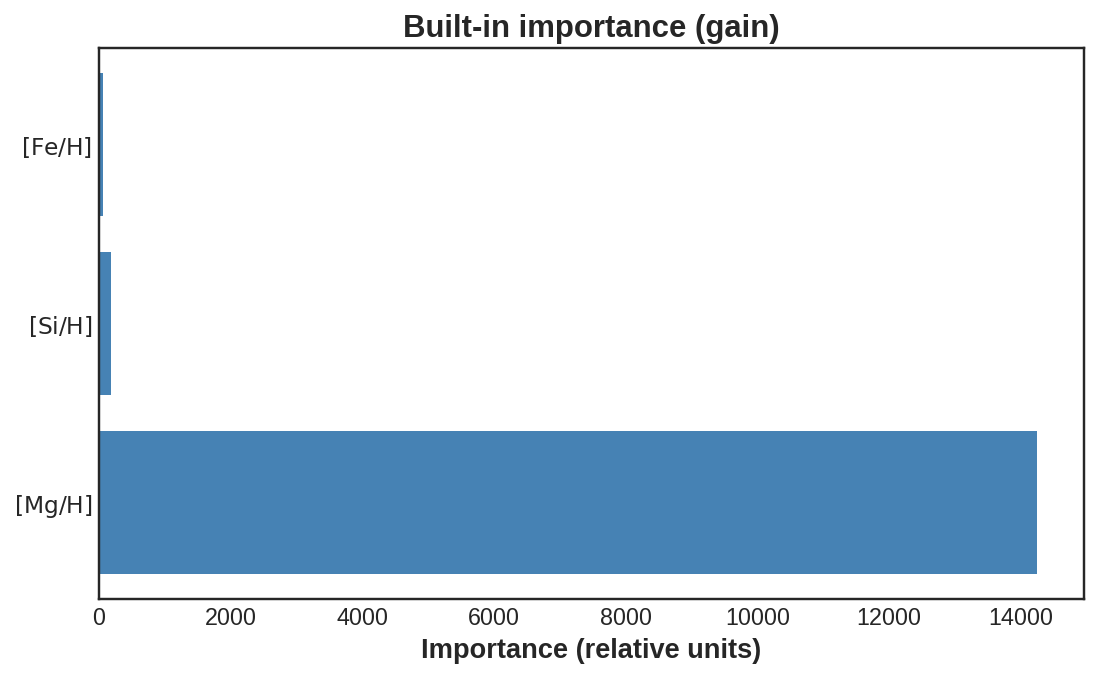

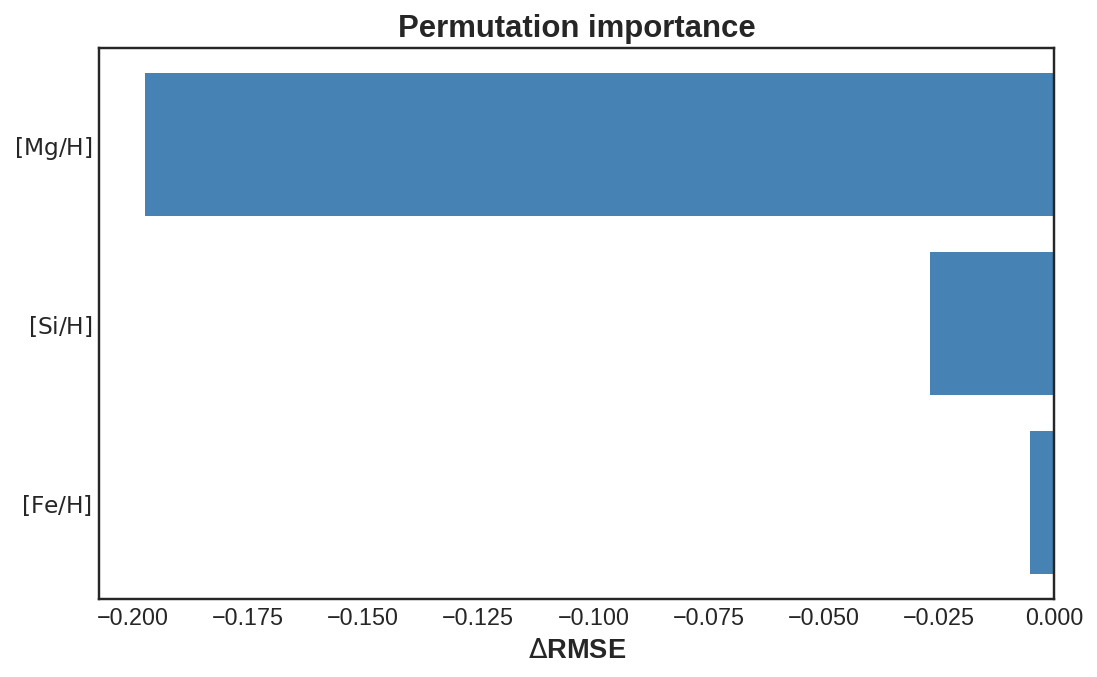

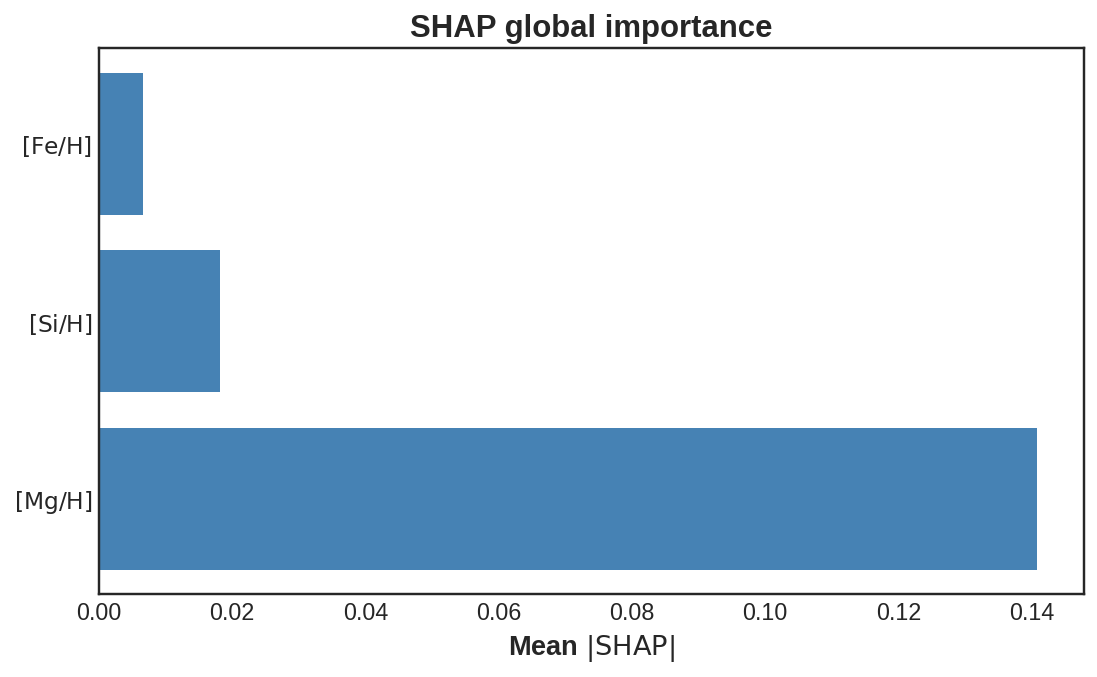

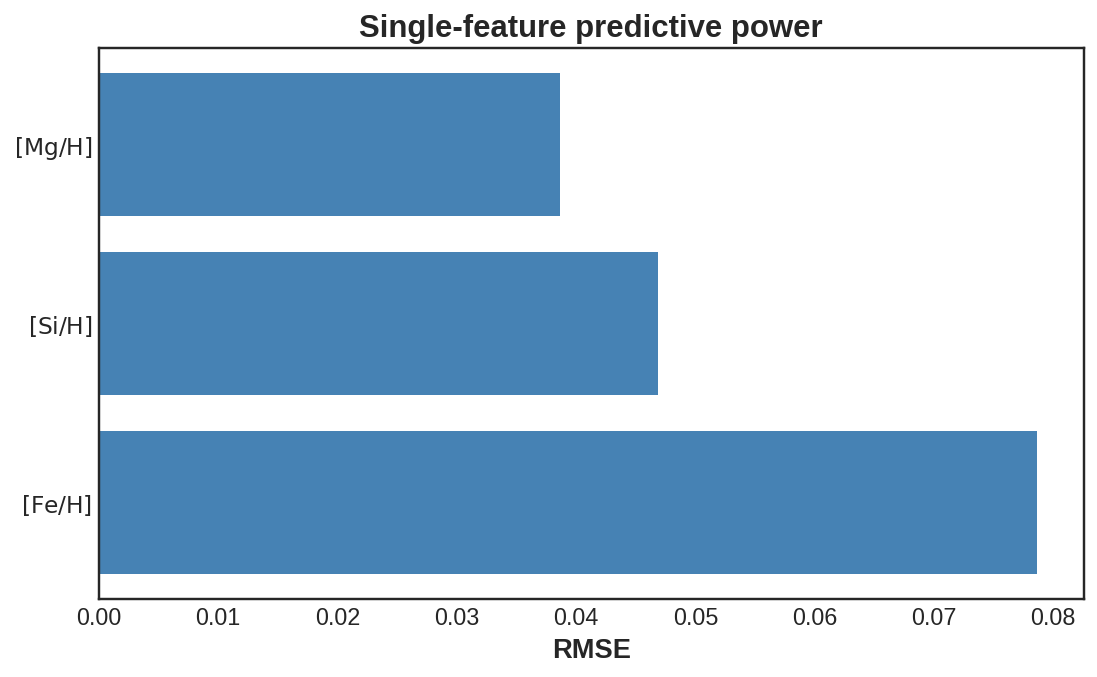

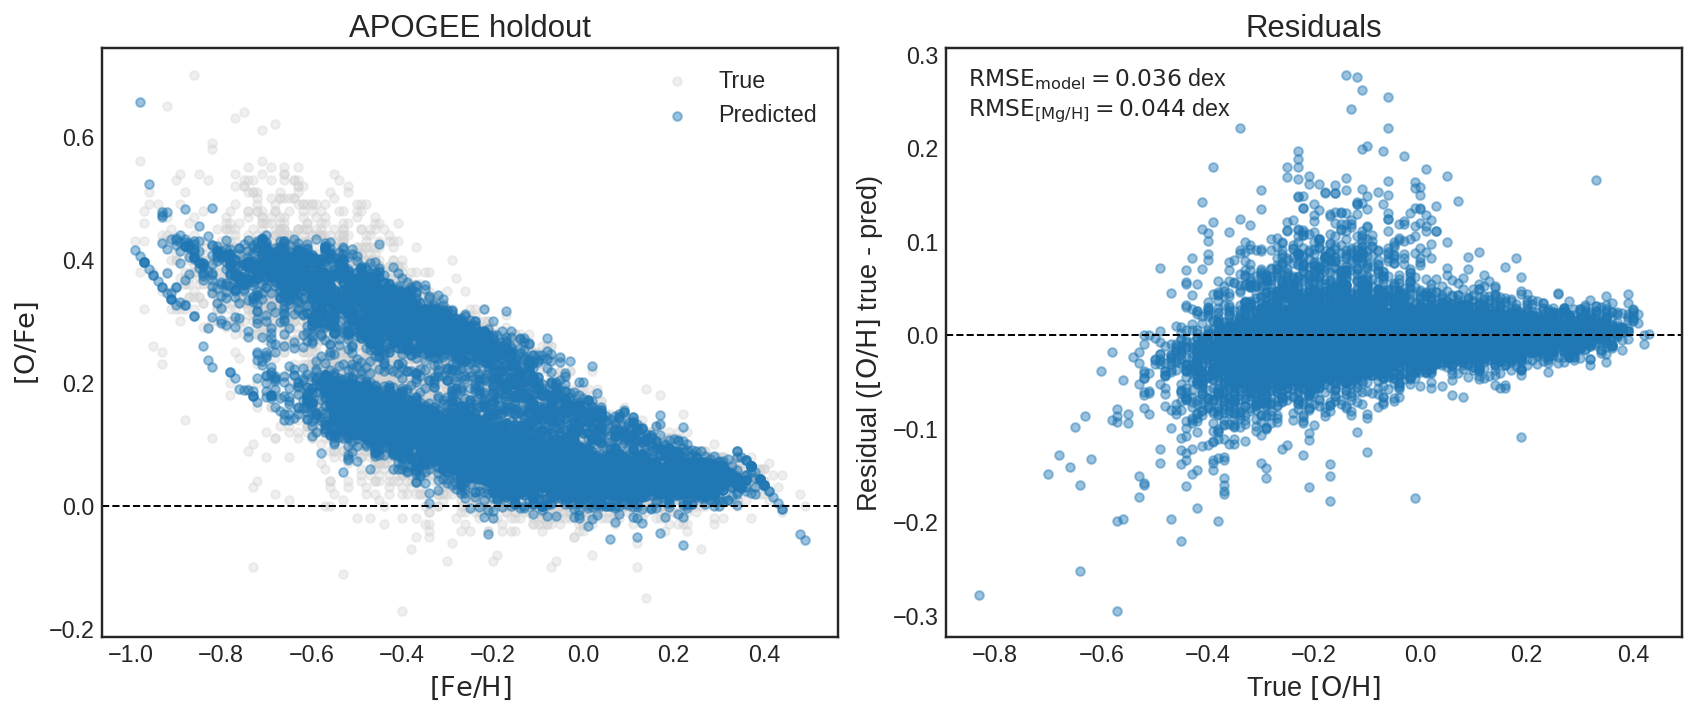

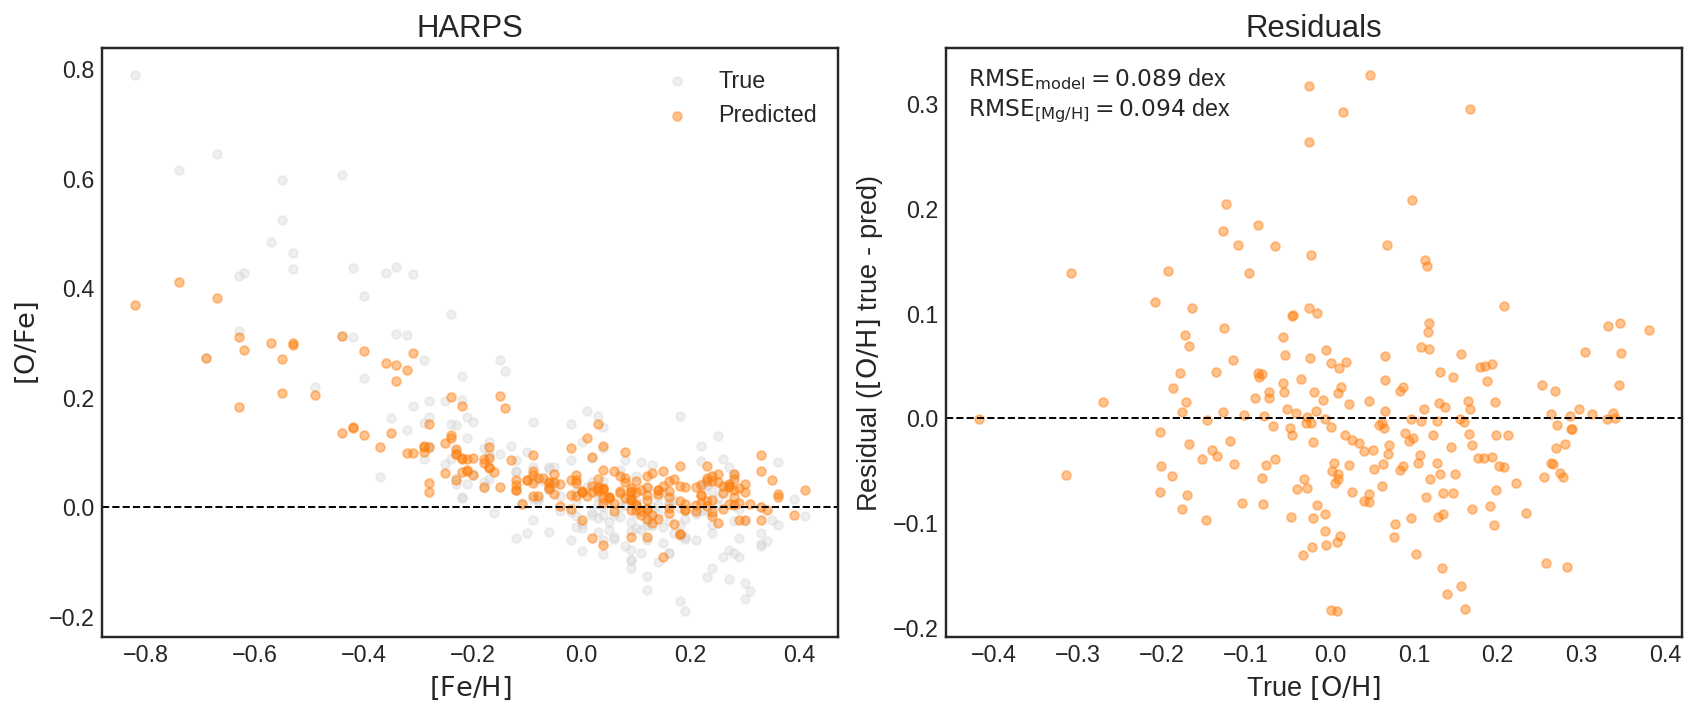

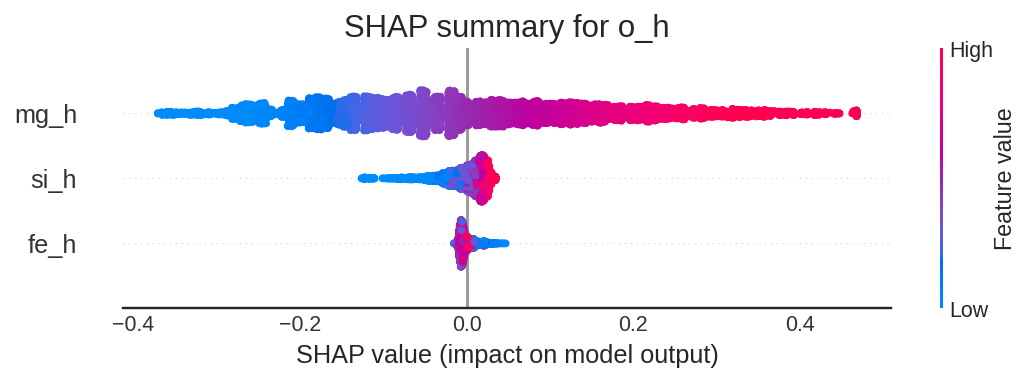

<Figure size 1120x840 with 0 Axes>

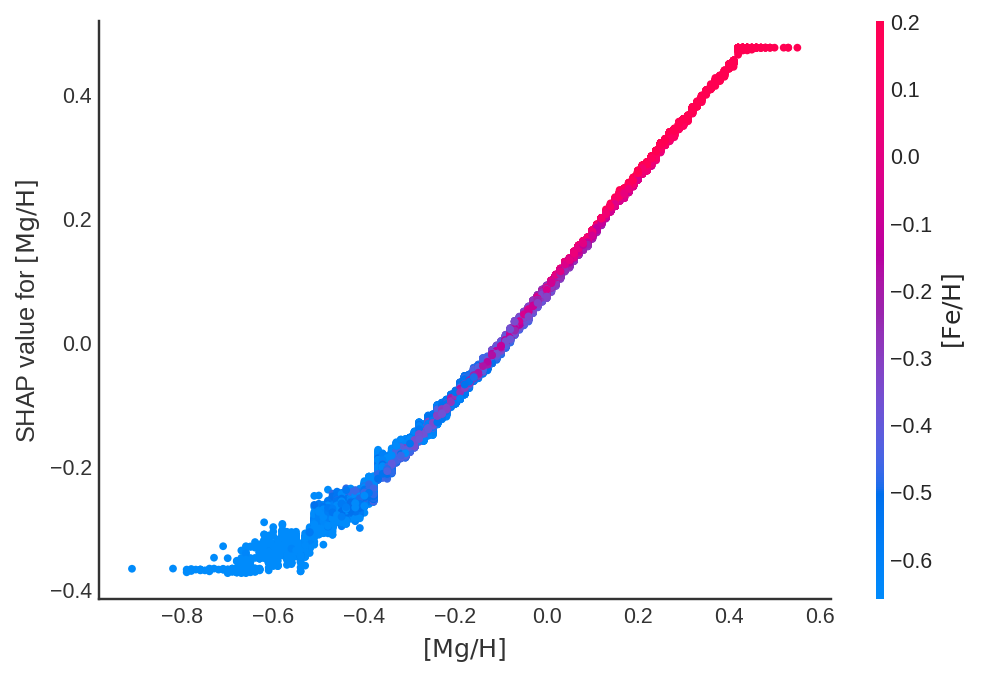

[I 2026-03-17 13:36:47,060] A new study created in memory with name: LGBM_c_h_fe_mg_si


Running pipeline for c_h


[I 2026-03-17 13:37:20,745] Trial 0 finished with value: 0.06673855820793503 and parameters: {'n_estimators': 610, 'learning_rate': 0.011954559491203725, 'num_leaves': 176, 'max_depth': 0, 'min_child_samples': 76, 'subsample': 0.7065384441162252, 'colsample_bytree': 0.6972543616789069, 'reg_alpha': 8.777720169239178, 'reg_lambda': 9.154732679032054e-08}. Best is trial 0 with value: 0.06673855820793503.
[I 2026-03-17 13:37:22,013] Trial 1 finished with value: 0.14115901499340058 and parameters: {'n_estimators': 84, 'learning_rate': 0.013480283033738506, 'num_leaves': 123, 'max_depth': 1, 'min_child_samples': 37, 'subsample': 0.6457053804135642, 'colsample_bytree': 0.949381753183971, 'reg_alpha': 1.7772969309552582e-07, 'reg_lambda': 2.5909721481556074e-05}. Best is trial 0 with value: 0.06673855820793503.
[I 2026-03-17 13:37:31,101] Trial 2 finished with value: 0.0672182462376943 and parameters: {'n_estimators': 763, 'learning_rate': 0.030361412628603805, 'num_leaves': 37, 'max_depth': 

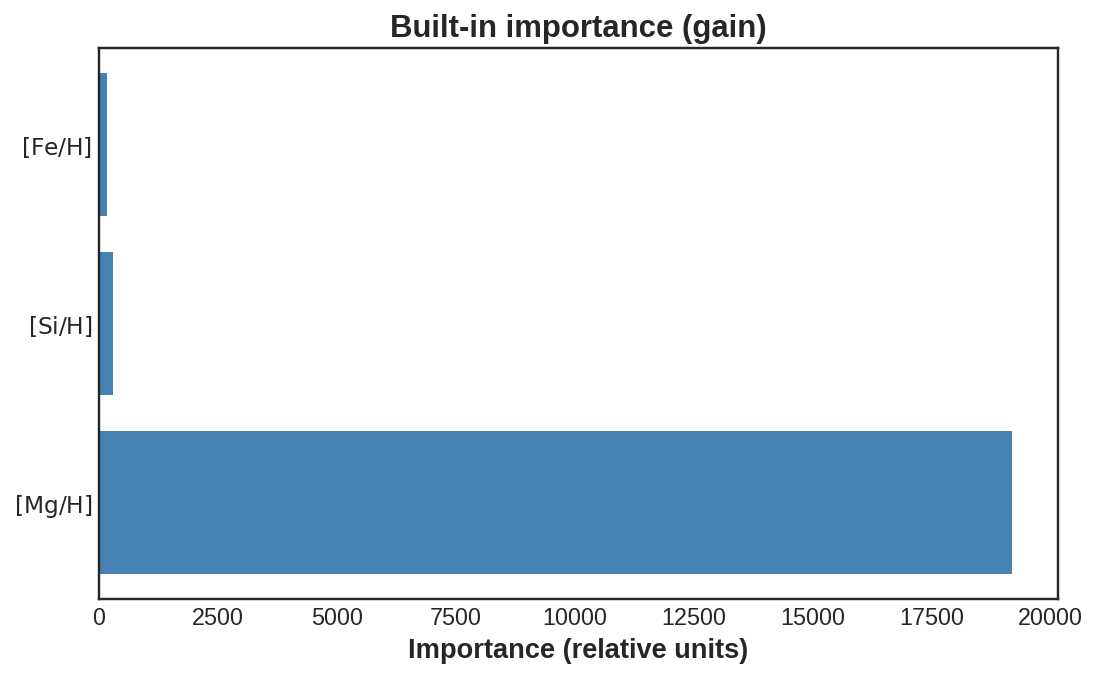

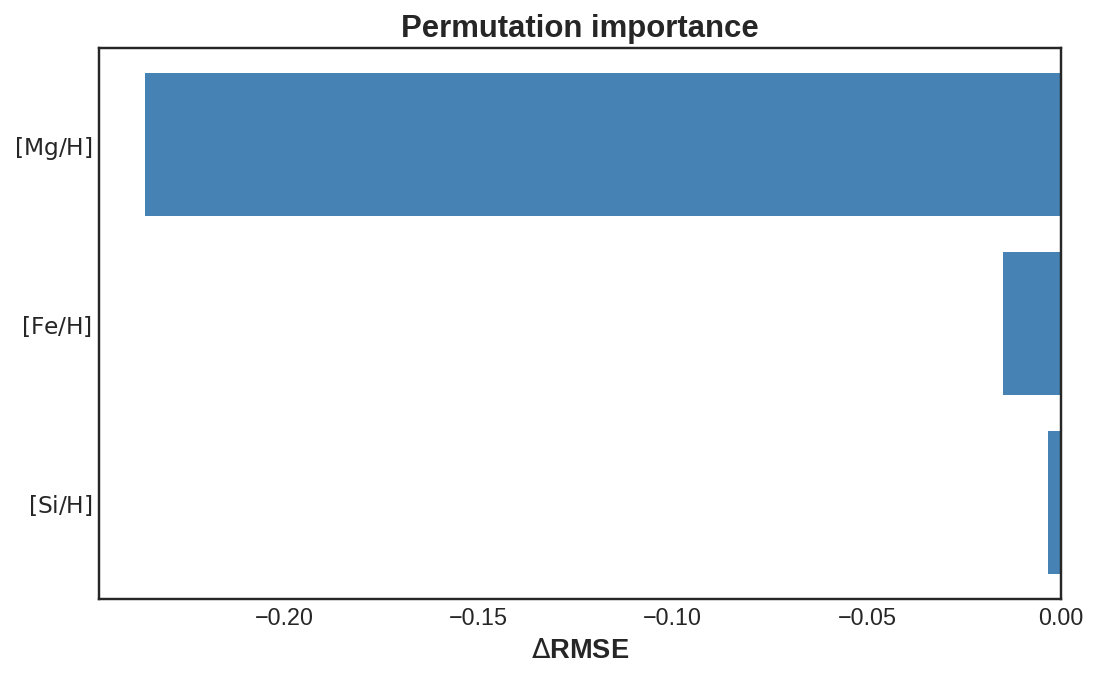

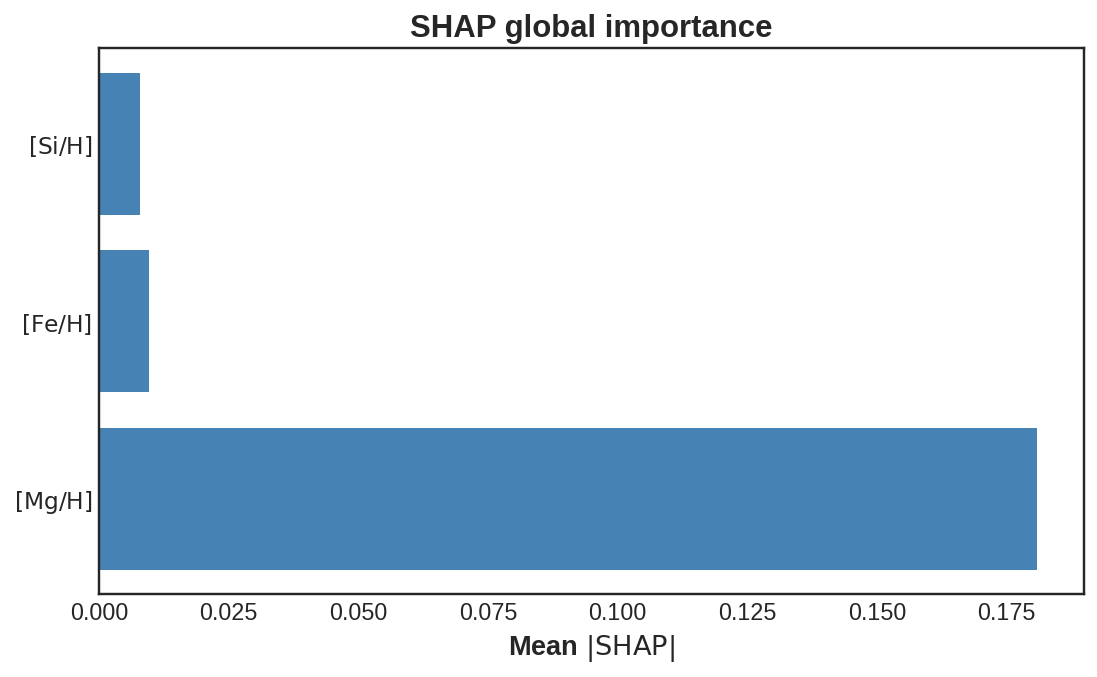

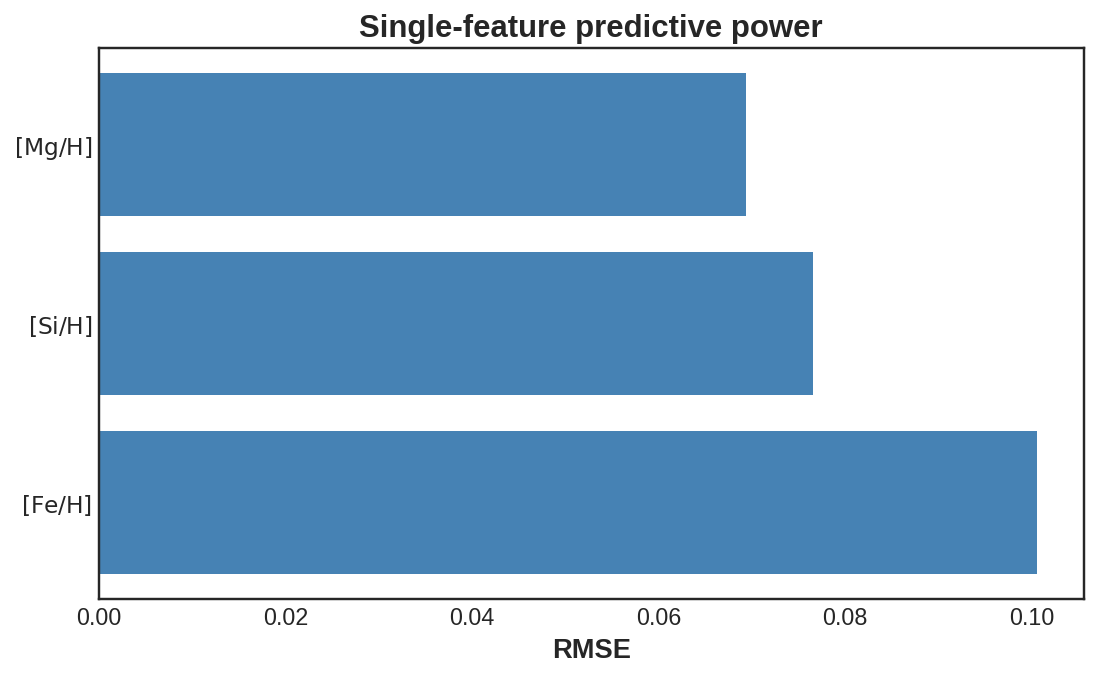

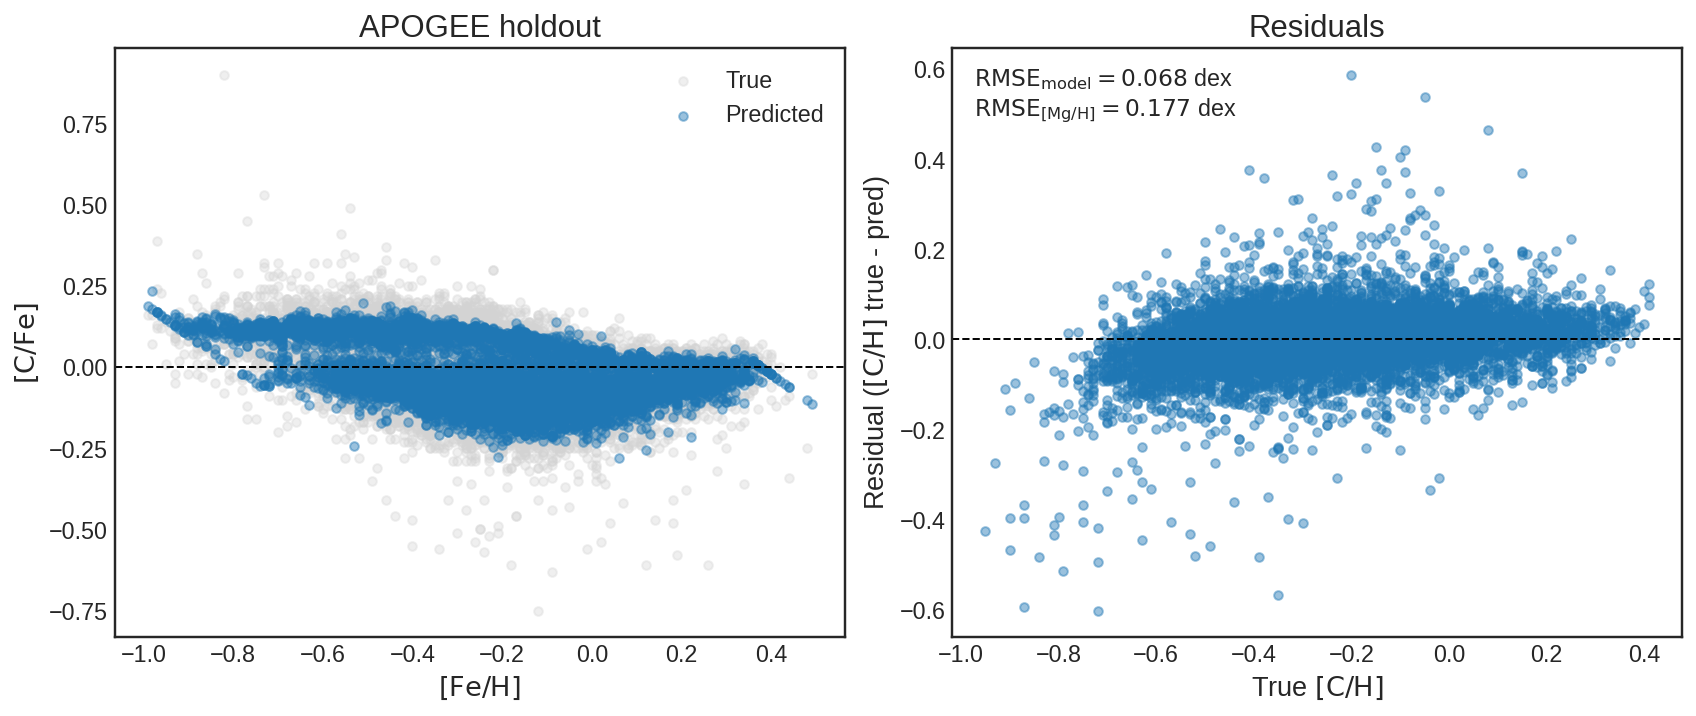

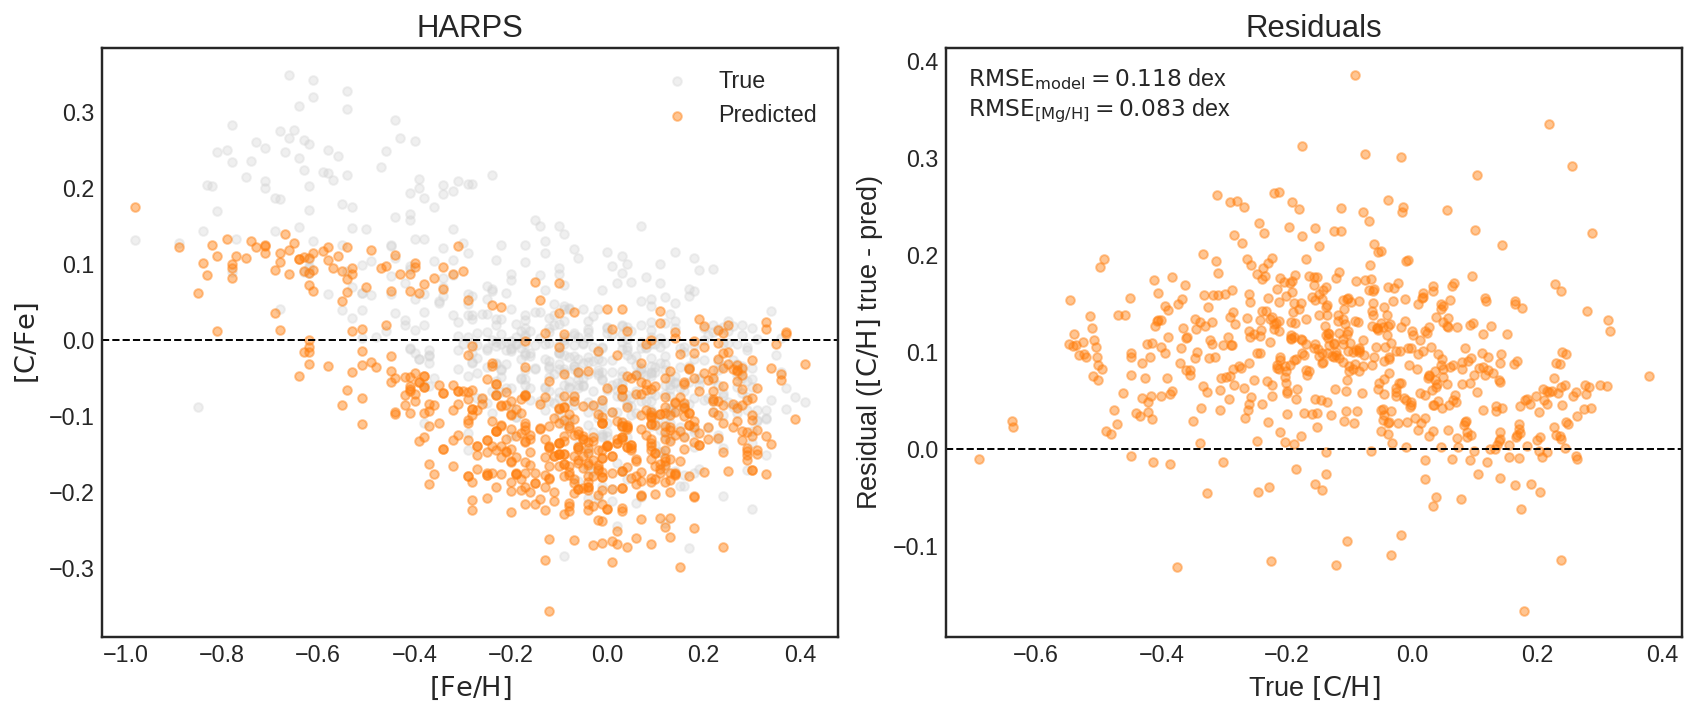

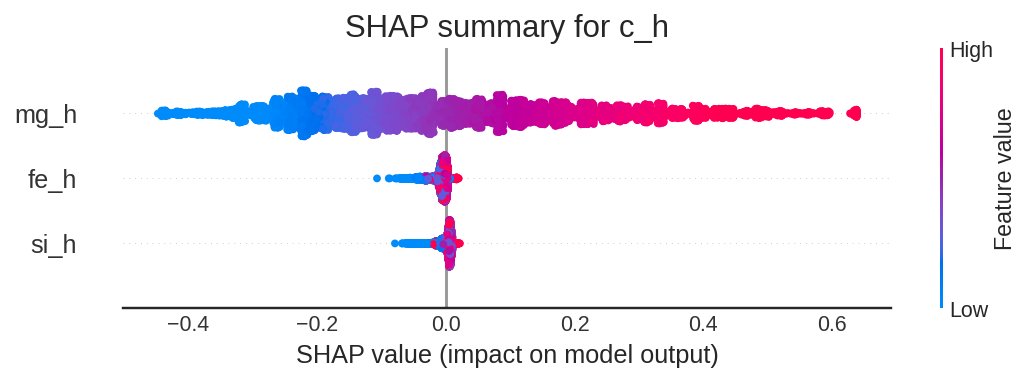

<Figure size 1120x840 with 0 Axes>

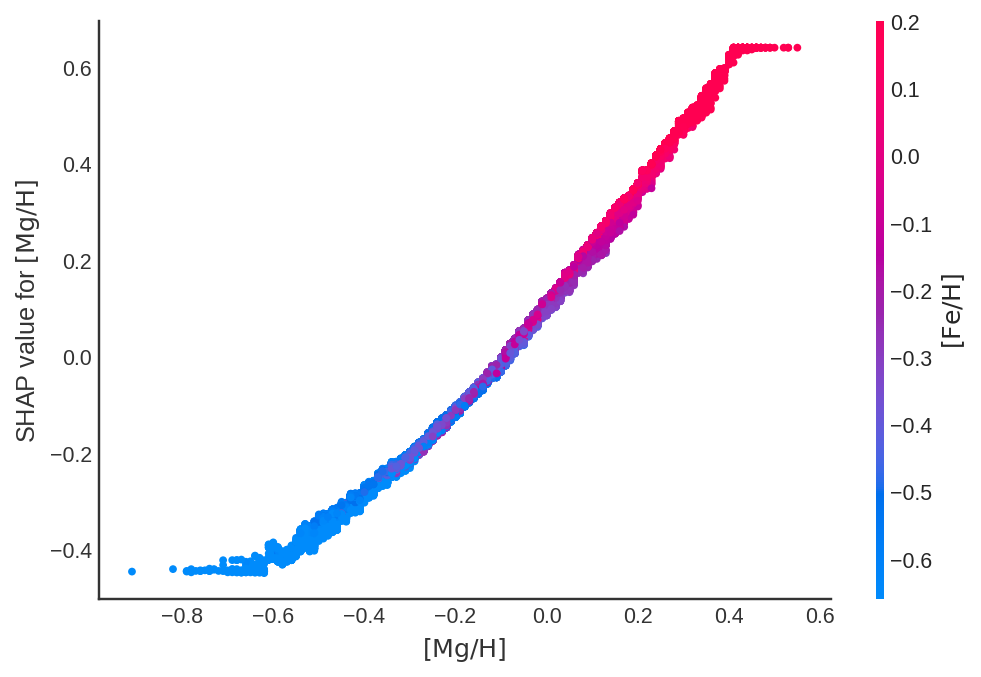

In [16]:
all_results = {}

for target in TARGETS:
    print(f"Running pipeline for {target}")
    all_results[target] = run_target_pipeline(apogee, harps, target)


In [17]:
compute_metrics(
    all_results["c_h"]["y_harps"],
    all_results["c_h"]["harps_pred"] + 0.1
)


{'rmse': 0.07289971246745297,
 'mae': 0.05573195497720419,
 'r2': 0.8883859572845876}

## Metrics summary

In [18]:
summary_rows = []
for target, result in all_results.items():
    summary_rows.append({
        "target": target,
        "best_cv_rmse": result["study"].best_value,
        "apogee_rmse": result["apogee_metrics"]["rmse"],
        "apogee_mae": result["apogee_metrics"]["mae"],
        "apogee_r2": result["apogee_metrics"]["r2"],
        "harps_rmse": result["harps_metrics"]["rmse"],
        "harps_mae": result["harps_metrics"]["mae"],
        "harps_r2": result["harps_metrics"]["r2"],
    })

metrics_df = pd.DataFrame(summary_rows)
metrics_df.round(4)


,target,best_cv_rmse,apogee_rmse,apogee_mae,apogee_r2,harps_rmse,harps_mae,harps_r2
0,o_h,0.0365,0.0363,0.0233,0.9649,0.0893,0.0637,0.6594
1,c_h,0.0654,0.0681,0.0467,0.9207,0.1179,0.1000,0.7079


## Importance summaries

In [19]:
for target in TARGETS:
    print("=" * 70)
    print(target)
    display(all_results[target]["importance_summary"].round(4))


o_h


,builtin_gain,permutation_drmse,shap_mean_abs,single_feature_cv_rmse,builtin_rank,permutation_rank,shap_rank,single_feature_rank
mg_h,14242.2545,-0.1974,0.1408,0.0387,1.0,3.0,1.0,1.0
si_h,188.9425,-0.0269,0.0182,0.0468,2.0,2.0,2.0,2.0
fe_h,60.0287,-0.0054,0.0066,0.0786,3.0,1.0,3.0,3.0


c_h


,builtin_gain,permutation_drmse,shap_mean_abs,single_feature_cv_rmse,builtin_rank,permutation_rank,shap_rank,single_feature_rank
mg_h,19204.0564,-0.2360,0.1808,0.0694,1.0,3.0,1.0,1.0
si_h,289.5295,-0.0033,0.0080,0.0766,2.0,1.0,3.0,2.0
fe_h,164.2095,-0.0150,0.0097,0.1006,3.0,2.0,2.0,3.0
